# Buy-only Monthly Investing with an ML Tilt — All-in-One Colab

Everything in one notebook: **config → data → features → model → simulation → this month's buy list**.

**How to run:** `Runtime → Run all`.
First run uses `SOURCE = "download"` (internet). Later runs can use `SOURCE = "file"` (cached data).

> The GitHub repo keeps the same code split into `.py` files (`src/`), as required by the project rubric.
> This notebook is the easiest way to run it end to end.

In [1]:
!pip install -q yfinance pyarrow

## (Optional) Keep cached data on Google Drive
Colab deletes local files when the session ends. Mount Drive if you want `SOURCE = "file"` to work in later sessions.

In [2]:
USE_DRIVE = False          # set True to cache data on Google Drive

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

## 0) Configuration

In [3]:
# =============================================================================
# CONFIG — every tunable setting in one place (accessed as cfg.NAME)
# =============================================================================
class cfg:
    # ---------------------------------------------------------------------------
    # Universe
    # ---------------------------------------------------------------------------
    # Benchmark = the asset a passive investor would buy every month.
    # VWRL tracks the FTSE All-World index (large + mid caps, developed + emerging).
    # NOTE: verify the yfinance ticker on first download (alternatives: 'VWRL.L', 'VGWL.DE').
    BENCHMARK = "VWRL.AS"

    # Core = fixed part of the monthly plan (index ETFs).
    CORE = [
        "VWRL.AS",   # FTSE All-World
        "SPY",       # S&P 500
        "QQQ",       # Nasdaq 100
        "EXS1.DE",   # iShares Core DAX ETF (verify ticker; fallback: '^GDAXI' index)
    ]

    # Satellite = large US stocks the model can tilt towards (same US list as the course).
    # Known limitation: chosen with today's knowledge -> survivorship bias (see README).
    SATELLITE = ["MSFT", "AAPL", "GOOG", "NVDA", "AMZN", "META",
                 "BRK-B", "LLY", "AVGO", "V", "JPM"]

    ALL_TICKERS = list(dict.fromkeys(CORE + SATELLITE))   # de-duplicated, order kept

    # Macro series from FRED (downloaded as CSV, no API key needed)
    FRED_SERIES = ["DGS10", "DGS1"]          # 10Y and 1Y US Treasury yields
    VIX_TICKER = "^VIX"                      # market fear gauge (yfinance)

    # ---------------------------------------------------------------------------
    # Dates
    # ---------------------------------------------------------------------------
    START_DATE = "2011-01-01"     # extra history so 252-day features exist from 2012-2013
    TRAIN_END = "2019-12"         # last month of TRAIN
    VALID_END = "2021-12"         # last month of VALIDATION; TEST starts the month after
    EMBARGO_MONTHS = 6            # gap before each split: 6-month labels must not overlap

    # ---------------------------------------------------------------------------
    # Target and strategy
    # ---------------------------------------------------------------------------
    HORIZON_DAYS = 126            # ~6 months of trading days
    MONTHLY_CONTRIBUTION = 1000   # money invested every month (currency effects ignored)
    CORE_SHARE = 0.70             # 70% of each contribution goes to the core ETFs
    TOP_K = 3                     # number of satellite stocks bought per month
    PROBA_THRESHOLD = 0.55        # minimum predicted probability for a satellite pick
    DRAWDOWN_TRIGGER = -0.05      # strategy D: double the contribution below this drawdown
    DRAWDOWN_MULTIPLIER = 2.0
    FEE_RATE = 0.001              # 0.1% cost on every purchase (no sells in a buy-only plan)

    RANDOM_STATE = 42
    DATA_DIR = "data"             # local cache (NOT committed to GitHub, see .gitignore)
    OUTPUT_DIR = "outputs"

if USE_DRIVE:
    cfg.DATA_DIR = "/content/drive/MyDrive/sma_project/data"
print("Tickers:", cfg.ALL_TICKERS)

Tickers: ['VWRL.AS', 'SPY', 'QQQ', 'EXS1.DE', 'MSFT', 'AAPL', 'GOOG', 'NVDA', 'AMZN', 'META', 'BRK-B', 'LLY', 'AVGO', 'V', 'JPM']


## 1) Data loading functions  (= `src/data_loader.py`)

In [4]:
"""
Step 1 - Data loading.

Two regimes (see README):
  * download : fetch fresh data from yfinance and FRED, then cache it locally
  * file     : read the cached files only (fast, reproducible, no internet needed)
"""
import io
import os
import time

import pandas as pd
import requests


# ---------------------------------------------------------------------------
# Storage helpers: parquet if pyarrow is installed, otherwise compressed CSV
# ---------------------------------------------------------------------------
def save_df(df: pd.DataFrame, path_no_ext: str) -> str:
    os.makedirs(os.path.dirname(path_no_ext) or ".", exist_ok=True)
    try:
        path = path_no_ext + ".parquet"
        df.to_parquet(path, index=False)
    except ImportError:
        path = path_no_ext + ".csv.gz"
        df.to_csv(path, index=False)
    return path


def load_df(path_no_ext: str) -> pd.DataFrame:
    if os.path.exists(path_no_ext + ".parquet"):
        df = pd.read_parquet(path_no_ext + ".parquet")
    elif os.path.exists(path_no_ext + ".csv.gz"):
        df = pd.read_csv(path_no_ext + ".csv.gz")
    else:
        raise FileNotFoundError(f"No cached file for {path_no_ext}. Run with --source download first.")
    if "Date" in df.columns:
        df["Date"] = pd.to_datetime(df["Date"])
    return df


# ---------------------------------------------------------------------------
# Prices (yfinance)
# ---------------------------------------------------------------------------
def download_prices(tickers, start: str, pause: float = 0.5) -> pd.DataFrame:
    """
    Download daily adjusted close prices.

    Returns a LONG table: Date | Ticker | Close | Volume
    Adjusted prices (auto_adjust=True) include dividends, so buy-and-hold
    returns already contain reinvested dividends.
    """
    import yfinance as yf            # imported here so 'file' mode works without yfinance

    frames, failed = [], []
    for ticker in tickers:
        try:
            hist = yf.Ticker(ticker).history(start=start, interval="1d", auto_adjust=True)
            if hist.empty:           # delisted / wrong ticker -> empty frame, not an exception
                failed.append(ticker)
                continue
            idx = hist.index
            # Drop the timezone but KEEP the local trading date.
            # (tz_convert(None) would shift European dates to the previous day in UTC.)
            if idx.tz is not None:
                idx = idx.tz_localize(None)
            frames.append(pd.DataFrame({
                "Date": idx.normalize(),
                "Ticker": ticker,
                "Close": hist["Close"].to_numpy(),
                "Volume": hist["Volume"].to_numpy(),
            }))
        except Exception as exc:     # network errors etc. -> skip ticker, report later
            print(f"  ! {ticker}: {type(exc).__name__}")
            failed.append(ticker)
        time.sleep(pause)            # be polite to Yahoo (avoid rate limits)

    if failed:
        print(f"  Failed tickers: {failed}")
    prices = pd.concat(frames, ignore_index=True)
    return prices.sort_values(["Ticker", "Date"]).reset_index(drop=True)


# ---------------------------------------------------------------------------
# Macro (FRED CSV endpoint + VIX from yfinance)
# ---------------------------------------------------------------------------
def download_fred(series_ids, start: str) -> pd.DataFrame:
    """Download FRED series as CSV (no API key). Missing values ('.') become NaN."""
    out = []
    for sid in series_ids:
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        df = pd.read_csv(io.StringIO(resp.text))
        df.columns = ["Date", sid]                       # header name changed over time
        df["Date"] = pd.to_datetime(df["Date"])
        df[sid] = pd.to_numeric(df[sid], errors="coerce")
        out.append(df.set_index("Date"))
    macro = pd.concat(out, axis=1).sort_index()
    return macro[macro.index >= start].reset_index()


def download_macro(fred_series, vix_ticker: str, start: str) -> pd.DataFrame:
    """Daily macro table: Date | DGS10 | DGS1 | VIX"""
    fred = download_fred(fred_series, start)
    vix = download_prices([vix_ticker], start)[["Date", "Close"]].rename(columns={"Close": "VIX"})
    macro = fred.merge(vix, on="Date", how="outer").sort_values("Date")
    return macro.reset_index(drop=True)


# ---------------------------------------------------------------------------
# Entry point used by the pipeline
# ---------------------------------------------------------------------------
def load_data(source: str, cfg):
    """source='download' -> fetch + cache;  source='file' -> read cache only."""
    prices_path = os.path.join(cfg.DATA_DIR, "prices")
    macro_path = os.path.join(cfg.DATA_DIR, "macro")

    if source == "download":
        print("Downloading prices ...")
        prices = download_prices(cfg.ALL_TICKERS, cfg.START_DATE)
        print("Downloading macro ...")
        macro = download_macro(cfg.FRED_SERIES, cfg.VIX_TICKER, cfg.START_DATE)
        print("  saved:", save_df(prices, prices_path), "|", save_df(macro, macro_path))
    elif source == "file":
        prices, macro = load_df(prices_path), load_df(macro_path)
    else:
        raise ValueError("source must be 'download' or 'file'")

    print(f"Prices: {len(prices):,} rows, {prices.Ticker.nunique()} tickers, "
          f"{prices.Date.min().date()} -> {prices.Date.max().date()}")
    return prices, macro

## 2) Feature engineering functions  (= `src/features.py`)

In [5]:
"""
Step 2 - Feature engineering and the monthly modelling table.

Pipeline:
  daily prices -> per-ticker daily features -> + benchmark-relative features
  -> + macro features -> sample the FIRST trading day of each month
  -> + cross-sectional ranks and dummies -> one modelling DataFrame

Lessons from the course applied here:
  * all shift/rolling operations run inside groupby('Ticker')   (Module 2)
  * the target stays NaN when the future is unknown (no fake zeros) (Module 3)
  * rates enter as changes / spreads, not only raw levels        (Module 3)
"""
import numpy as np
import pandas as pd

GROWTH_WINDOWS = [21, 63, 126, 252]   # ~1, 3, 6, 12 months of trading days


# ---------------------------------------------------------------------------
# Per-ticker daily features
# ---------------------------------------------------------------------------
def _rsi(close: pd.Series, period: int = 14) -> pd.Series:
    """Wilder's RSI implemented with pandas (avoids the TA-Lib C dependency)."""
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / period, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / period, adjust=False).mean()
    rs = gain / loss.replace(0, np.nan)
    return 100 - 100 / (1 + rs)


def _as_ns(s: pd.Series) -> pd.Series:
    """Unify datetime resolution (merge_asof requires identical key dtypes)."""
    return pd.to_datetime(s).astype("datetime64[ns]")


def add_price_features(prices: pd.DataFrame, horizon: int) -> pd.DataFrame:
    df = prices.copy()
    df["Date"] = _as_ns(df["Date"])
    df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    g = df.groupby("Ticker")["Close"]

    for n in GROWTH_WINDOWS:                                    # momentum features (past)
        df[f"growth_{n}d"] = g.transform(lambda s, n=n: s / s.shift(n))

    daily_ret = g.transform(lambda s: s.pct_change())
    # Volatility on RETURNS (not on price levels), annualised with sqrt(252)
    df["vol_63d"] = daily_ret.groupby(df["Ticker"]).transform(lambda s: s.rolling(63).std() * np.sqrt(252))
    df["rsi_14"] = g.transform(_rsi)
    df["dist_52w_high"] = g.transform(lambda s: s / s.rolling(252, min_periods=60).max() - 1)
    df["dist_52w_low"] = g.transform(lambda s: s / s.rolling(252, min_periods=60).min() - 1)

    # Future growth = what we want to predict (NaN for the last `horizon` days)
    df[f"future_growth_{horizon}d"] = g.transform(lambda s: s.shift(-horizon) / s)
    return df


# ---------------------------------------------------------------------------
# Benchmark-relative features and target
# ---------------------------------------------------------------------------
def add_benchmark_features(df: pd.DataFrame, benchmark: str, horizon: int) -> pd.DataFrame:
    fut = f"future_growth_{horizon}d"
    bench = df.loc[df.Ticker == benchmark, ["Date", "Close", "growth_126d", fut]].copy()
    # All-time-high drawdown of the benchmark (used by strategy D and as a feature)
    bench["bench_drawdown"] = bench["Close"] / bench["Close"].cummax() - 1
    bench = bench.rename(columns={"growth_126d": "bench_growth_126d", fut: "bench_" + fut}).drop(columns="Close")

    # merge_asof: each asset row gets the latest benchmark value on/before its date
    # (handles different exchange holidays between US and European listings)
    df = pd.merge_asof(df.sort_values("Date"), bench.sort_values("Date"), on="Date", direction="backward")

    df["rel_growth_126d"] = df["growth_126d"] - df["bench_growth_126d"]
    df["excess_future_growth"] = df[fut] - df["bench_" + fut]

    # TARGET: 1 if the asset beats the benchmark over the next 6 months.
    # Kept as NaN when the future is unknown -> such rows are excluded from training.
    known = df["excess_future_growth"].notna()
    df["is_outperform_6m"] = np.where(known, (df["excess_future_growth"] > 0).astype(float), np.nan)
    # The benchmark cannot beat itself -> no label (keeps it out of training)
    df.loc[df["Ticker"] == benchmark, "is_outperform_6m"] = np.nan
    return df


# ---------------------------------------------------------------------------
# Macro features
# ---------------------------------------------------------------------------
def add_macro_features(df: pd.DataFrame, macro: pd.DataFrame) -> pd.DataFrame:
    m = macro.copy()
    m["Date"] = _as_ns(m["Date"])
    m = m.sort_values("Date")
    m[["DGS10", "DGS1", "VIX"]] = m[["DGS10", "DGS1", "VIX"]].ffill()   # forward-fill only (no look-ahead)
    m["term_spread"] = m["DGS10"] - m["DGS1"]              # >0 normal, <0 inverted curve
    m["dgs10_chg_63d"] = m["DGS10"] - m["DGS10"].shift(63)  # 3-month change in long rates
    m["vix_chg_21d"] = m["VIX"] / m["VIX"].shift(21) - 1
    keep = ["Date", "DGS10", "term_spread", "dgs10_chg_63d", "VIX", "vix_chg_21d"]
    return pd.merge_asof(df.sort_values("Date"), m[keep], on="Date", direction="backward")


# ---------------------------------------------------------------------------
# Monthly table
# ---------------------------------------------------------------------------
RANK_COLS = ["growth_126d", "growth_252d", "rsi_14", "vol_63d", "dist_52w_high"]


def build_monthly_table(prices, macro, cfg):
    """Return (monthly_df, feature_sets dict)."""
    df = add_price_features(prices, cfg.HORIZON_DAYS)
    df = add_benchmark_features(df, cfg.BENCHMARK, cfg.HORIZON_DAYS)
    df = add_macro_features(df, macro)

    # One row per ticker and month: the first trading day = our monthly buying day
    df["ym"] = df["Date"].dt.to_period("M")
    first_idx = df.groupby(["Ticker", "ym"])["Date"].idxmin()
    monthly = df.loc[first_idx].sort_values(["ym", "Ticker"]).reset_index(drop=True)

    # Cross-sectional ranks: position of each asset vs. the others in the same month (0..1)
    for c in RANK_COLS:
        monthly[f"rank_{c}"] = monthly.groupby("ym")[c].rank(pct=True)

    # Dummies: calendar month + asset group
    monthly["month_name"] = monthly["Date"].dt.month_name()
    monthly["asset_group"] = np.where(monthly["Ticker"].isin(cfg.CORE), "core", "satellite")
    dummies = pd.get_dummies(monthly[["month_name", "asset_group"]], dtype="int8")
    monthly = pd.concat([monthly, dummies], axis=1)

    feature_sets = {
        "GROWTH": [f"growth_{n}d" for n in GROWTH_WINDOWS] + ["rel_growth_126d"],
        "TECHNICAL": ["vol_63d", "rsi_14", "dist_52w_high", "dist_52w_low"],
        "MACRO": ["DGS10", "term_spread", "dgs10_chg_63d", "VIX", "vix_chg_21d", "bench_drawdown"],
        "RANKS": [f"rank_{c}" for c in RANK_COLS],
        "DUMMIES": dummies.columns.tolist(),
        "TO_PREDICT": ["is_outperform_6m", "excess_future_growth", f"future_growth_{cfg.HORIZON_DAYS}d"],
    }
    feature_sets["NUMERICAL"] = (feature_sets["GROWTH"] + feature_sets["TECHNICAL"]
                                 + feature_sets["MACRO"] + feature_sets["RANKS"])
    feature_sets["FEATURES"] = feature_sets["NUMERICAL"] + feature_sets["DUMMIES"]
    return monthly, feature_sets

## 3) Modelling functions  (= `src/modeling.py`)

In [6]:
"""
Step 3 - Temporal split, model tuning and predictions.

Models (from the lectures): DecisionTreeClassifier, RandomForestClassifier.
Selection metric: precision on VALIDATION (as in Modules 3-4), because a buy
signal matters only when the model says "buy".
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score
from sklearn.tree import DecisionTreeClassifier

TARGET = "is_outperform_6m"


# ---------------------------------------------------------------------------
# Temporal split with an embargo
# ---------------------------------------------------------------------------
def add_split(monthly: pd.DataFrame, train_end: str, valid_end: str) -> pd.DataFrame:
    ym = monthly["ym"]
    monthly["split"] = np.where(ym <= pd.Period(train_end, "M"), "train",
                       np.where(ym <= pd.Period(valid_end, "M"), "validation", "test"))
    return monthly


def fit_mask(monthly, upto_split: str, embargo_months: int, train_end, valid_end):
    """
    Rows usable for fitting a model that will be evaluated on the NEXT split.

    A 6-month label starting less than 6 months before the next split overlaps
    that split's period, so those rows are dropped (embargo) to avoid leakage.
    """
    boundary = pd.Period(train_end if upto_split == "train" else valid_end, "M")
    allowed = ["train"] if upto_split == "train" else ["train", "validation"]
    return (monthly["split"].isin(allowed)
            & (monthly["ym"] <= boundary - embargo_months)
            & monthly[TARGET].notna())


def make_X(monthly: pd.DataFrame, features) -> pd.DataFrame:
    """Same cleaning as the course: inf -> NaN -> 0."""
    return monthly[features].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")


# ---------------------------------------------------------------------------
# Hyperparameter tuning on VALIDATION
# ---------------------------------------------------------------------------
def _make_model(kind: str, depth: int, seed: int):
    if kind == "DecisionTree":
        return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=10, random_state=seed)
    return RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=10,
                                  n_jobs=-1, random_state=seed)


def tune_models(monthly, features, cfg, threshold: float = 0.5, min_positive: int = 20):
    """
    Grid over model type x max_depth. Fit on TRAIN (with embargo), score on VALIDATION.
    Returns a results table sorted by validation precision.
    """
    fit_rows = fit_mask(monthly, "train", cfg.EMBARGO_MONTHS, cfg.TRAIN_END, cfg.VALID_END)
    val_rows = (monthly["split"] == "validation") & monthly[TARGET].notna()
    X_fit, y_fit = make_X(monthly[fit_rows], features), monthly.loc[fit_rows, TARGET]
    X_val, y_val = make_X(monthly[val_rows], features), monthly.loc[val_rows, TARGET]

    rows = []
    for kind in ["DecisionTree", "RandomForest"]:
        for depth in range(2, 9):
            model = _make_model(kind, depth, cfg.RANDOM_STATE).fit(X_fit, y_fit)
            pred = (model.predict_proba(X_val)[:, 1] >= threshold).astype(int)
            n_pos = int(pred.sum())
            prec = precision_score(y_val, pred, zero_division=0) if n_pos >= min_positive else np.nan
            rows.append({"model": kind, "max_depth": depth, "val_precision": prec, "val_n_positive": n_pos})

    res = pd.DataFrame(rows).sort_values("val_precision", ascending=False, na_position="last")
    print(f"Base rate (validation): {y_val.mean():.3f}  | train rows {len(y_fit)}, validation rows {len(y_val)}")
    return res.reset_index(drop=True)


# ---------------------------------------------------------------------------
# Final model and predictions for every row (incl. the latest, unlabeled month)
# ---------------------------------------------------------------------------
def fit_final_and_predict(monthly, features, cfg, kind: str, depth: int):
    rows = fit_mask(monthly, "validation", cfg.EMBARGO_MONTHS, cfg.TRAIN_END, cfg.VALID_END)
    model = _make_model(kind, depth, cfg.RANDOM_STATE).fit(make_X(monthly[rows], features),
                                                          monthly.loc[rows, TARGET])
    monthly["proba"] = model.predict_proba(make_X(monthly, features))[:, 1]
    return model, monthly


def test_report(monthly, thresholds=(0.5, 0.55, 0.6)) -> pd.DataFrame:
    """
    Precision and number of signals on TEST for several decision thresholds.

    n_months matters: all assets are compared with the SAME benchmark, so in a
    month when the benchmark does badly almost every asset "outperforms".
    Signals concentrated in a few months can show high precision by luck
    (observed in a synthetic-data smoke test: 0.80 precision on pure noise).
    """
    t = monthly[(monthly["split"] == "test") & monthly[TARGET].notna()]
    out = [{"threshold": "base rate", "n_signals": len(t), "n_months": t["ym"].nunique(),
            "precision": t[TARGET].mean()}]
    for thr in thresholds:
        sel = t[t["proba"] >= thr]
        out.append({"threshold": thr, "n_signals": len(sel), "n_months": sel["ym"].nunique(),
                    "precision": sel[TARGET].mean() if len(sel) else np.nan})
    return pd.DataFrame(out)


def feature_importance(model, features, top: int = 15) -> pd.Series:
    return pd.Series(model.feature_importances_, index=features).sort_values(ascending=False).head(top)

## 4) Simulation functions  (= `src/simulation.py`)

In [7]:
"""
Step 4 - Buy-only monthly investing simulation (dollar-cost averaging).

Every month a fixed contribution is split across assets according to a weight
table (month x ticker). Nothing is ever sold. The simulation is fully
vectorised and exact: units bought = money / price, holdings accumulate, and
dividends are included because prices are dividend-adjusted.

Metrics
  * IRR (money-weighted, annualised): the right return measure when money is
    added every month (a simple CAGR assumes one initial deposit)
  * TWR CAGR and max drawdown on a time-weighted index (removes the effect of
    the inflows themselves)
"""
import numpy as np
import pandas as pd


# ---------------------------------------------------------------------------
# Inputs
# ---------------------------------------------------------------------------
def price_matrix(monthly: pd.DataFrame) -> pd.DataFrame:
    """Month x ticker table of buying prices (close on the first trading day)."""
    return monthly.pivot_table(index="ym", columns="Ticker", values="Close", aggfunc="first").sort_index()


def contribution_series(monthly, pm, cfg, buy_the_dip: bool) -> pd.Series:
    """Fixed monthly amount; doubled when the benchmark is in a drawdown (strategy D)."""
    cash = pd.Series(float(cfg.MONTHLY_CONTRIBUTION), index=pm.index)
    if buy_the_dip:
        dd = (monthly[monthly.Ticker == cfg.BENCHMARK].set_index("ym")["bench_drawdown"]
              .reindex(pm.index))
        cash[dd <= cfg.DRAWDOWN_TRIGGER] *= cfg.DRAWDOWN_MULTIPLIER
    return cash


# ---------------------------------------------------------------------------
# Weight tables (each row sums to 1)
# ---------------------------------------------------------------------------
def _equal(pm, tickers, share=1.0):
    w = pd.DataFrame(0.0, index=pm.index, columns=pm.columns)
    cols = [t for t in tickers if t in pm.columns]
    avail = pm[cols].notna()                                  # only assets with a price that month
    w[cols] = avail.div(avail.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * share
    return w


def weights_passive(pm, cfg):
    return _equal(pm, [cfg.BENCHMARK])


def weights_core(pm, cfg):
    return _equal(pm, cfg.CORE)


def weights_core_satellite(monthly, pm, cfg, use_model: bool = True):
    """
    Core share split equally across core ETFs.
    Satellite share: top-K satellite stocks by predicted probability (>= threshold).
    If fewer than K qualify, the unused part goes to the benchmark.
    use_model=False -> satellite share split equally across ALL satellite stocks
    (a 'no-ML' baseline that isolates the value of the model).
    """
    sat_share = 1 - cfg.CORE_SHARE
    w = _equal(pm, cfg.CORE, share=cfg.CORE_SHARE)
    if not use_model:
        return w + _equal(pm, cfg.SATELLITE, share=sat_share)

    cand = monthly[monthly.Ticker.isin(cfg.SATELLITE) & (monthly.proba >= cfg.PROBA_THRESHOLD)]
    for ym, grp in cand.groupby("ym"):
        picks = grp.nlargest(cfg.TOP_K, "proba")["Ticker"].tolist()
        for t in picks:
            w.loc[ym, t] += sat_share / cfg.TOP_K
        w.loc[ym, cfg.BENCHMARK] += sat_share * (cfg.TOP_K - len(picks)) / cfg.TOP_K
    no_pick = ~w.index.isin(cand["ym"].unique())               # months without any pick
    w.loc[no_pick, cfg.BENCHMARK] += sat_share
    return w


# ---------------------------------------------------------------------------
# Simulation and metrics
# ---------------------------------------------------------------------------
def _irr_annual(cash_flows: np.ndarray) -> float:
    """Monthly IRR by bisection (no extra dependency), annualised."""
    t = np.arange(len(cash_flows))
    npv = lambda r: np.sum(cash_flows / (1 + r) ** t)
    lo, hi = -0.5, 0.5
    if npv(lo) * npv(hi) > 0:
        return np.nan
    for _ in range(200):
        mid = (lo + hi) / 2
        if npv(lo) * npv(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return (1 + mid) ** 12 - 1


def run_dca(pm: pd.DataFrame, weights: pd.DataFrame, cash: pd.Series, fee_rate: float = 0.0):
    """Vectorised buy-only simulation. Returns (summary dict, value series)."""
    w = weights.where(pm.notna(), 0)
    w = w.div(w.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)   # renormalise if a price is missing
    units = w.mul(cash * (1 - fee_rate), axis=0) / pm               # units bought each month (after fees)
    holdings = units.fillna(0).cumsum()
    px = pm.ffill()                                                  # carry last price for valuation

    value = (holdings * px).sum(axis=1)                              # after this month's purchase
    value_before = (holdings.shift(1).fillna(0) * px).sum(axis=1)    # before this month's purchase
    ret = (value_before / value.shift(1) - 1).iloc[1:]               # time-weighted monthly returns
    twr = (1 + ret).cumprod()
    years = len(ret) / 12

    flows = -cash.to_numpy().copy()
    flows[-1] += value.iloc[-1]                                      # sell everything at the end (valuation only)
    summary = {
        "months": len(cash),
        "invested": cash.sum(),
        "final_value": value.iloc[-1],
        "profit_multiple": value.iloc[-1] / cash.sum(),
        "IRR": _irr_annual(flows),
        "TWR_CAGR": twr.iloc[-1] ** (1 / years) - 1 if years > 0 else np.nan,
        "max_drawdown": (twr / twr.cummax() - 1).min(),
    }
    return summary, value


def compare_strategies(monthly, cfg, period_mask=None):
    """Run all strategies on the same months and return (summary table, value curves)."""
    data = monthly if period_mask is None else monthly[period_mask]
    pm = price_matrix(data)
    plain = contribution_series(data, pm, cfg, buy_the_dip=False)
    dip = contribution_series(data, pm, cfg, buy_the_dip=True)

    strategies = {
        "A_passive_all_world": (weights_passive(pm, cfg), plain),
        "B_core_equal": (weights_core(pm, cfg), plain),
        "C0_core_satellite_no_ml": (weights_core_satellite(data, pm, cfg, use_model=False), plain),
        "C_core_satellite_ml": (weights_core_satellite(data, pm, cfg, use_model=True), plain),
        "D_ml_plus_buy_the_dip": (weights_core_satellite(data, pm, cfg, use_model=True), dip),
    }
    rows, curves = [], {}
    for name, (w, c) in strategies.items():
        s, v = run_dca(pm, w, c, fee_rate=cfg.FEE_RATE)
        rows.append({"strategy": name, **s})
        curves[name] = v
    return pd.DataFrame(rows), pd.DataFrame(curves)


# ---------------------------------------------------------------------------
# "What do I buy this month?"
# ---------------------------------------------------------------------------
def latest_buy_list(monthly, cfg) -> pd.DataFrame:
    last = monthly["ym"].max()
    data = monthly[monthly.ym == last]
    pm = price_matrix(data)
    w = weights_core_satellite(data, pm, cfg, use_model=True).iloc[0]
    cash = contribution_series(data, pm, cfg, buy_the_dip=True).iloc[0]
    out = (w[w > 0].rename("weight").to_frame()
           .assign(amount=lambda d: (d.weight * cash).round(2))
           .join(data.set_index("Ticker")[["Close", "proba"]]))
    out.index.name = f"buy list {last}"
    return out.sort_values("amount", ascending=False)

---
# Run the workflow
## Step 1 — Data

In [8]:
import os
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

SOURCE = "download"        # first run: "download"; afterwards "file"
prices, macro = load_data(SOURCE, cfg)
prices.groupby("Ticker")["Date"].agg(["min", "max", "count"])

  saved: data/prices.parquet | data/macro.parquet
Prices: 59,340 rows, 15 tickers, 2011-01-03 -> 2026-11-20


,min,max,count
Ticker,,,
AAPL,2011-01-03,2026-11-20,3996
AMZN,2011-01-03,2026-11-20,3996
AVGO,2011-01-03,2026-11-20,3996
BRK-B,2011-01-03,2026-11-20,3996
EXS1.DE,2011-01-03,2026-11-20,4033
GOOG,2011-01-03,2026-11-20,3996
JPM,2011-01-03,2026-11-20,3996
LLY,2011-01-03,2026-11-20,3996
META,2012-05-18,2026-11-20,3649


## Step 2 — Monthly table and feature sets

In [9]:
monthly, fs = build_monthly_table(prices, macro, cfg)
monthly = add_split(monthly, cfg.TRAIN_END, cfg.VALID_END)
FEATURES = fs["FEATURES"]
for k, v in fs.items():
    print(f"{k:<11} ({len(v)}): {v}")
monthly.groupby("split")["ym"].agg(["min", "max", "count"])

GROWTH      (5): ['growth_21d', 'growth_63d', 'growth_126d', 'growth_252d', 'rel_growth_126d']
TECHNICAL   (4): ['vol_63d', 'rsi_14', 'dist_52w_high', 'dist_52w_low']
MACRO       (6): ['DGS10', 'term_spread', 'dgs10_chg_63d', 'VIX', 'vix_chg_21d', 'bench_drawdown']
RANKS       (5): ['rank_growth_126d', 'rank_growth_252d', 'rank_rsi_14', 'rank_vol_63d', 'rank_dist_52w_high']
DUMMIES     (14): ['month_name_April', 'month_name_August', 'month_name_December', 'month_name_February', 'month_name_January', 'month_name_July', 'month_name_June', 'month_name_March', 'month_name_May', 'month_name_November', 'month_name_October', 'month_name_September', 'asset_group_core', 'asset_group_satellite']
TO_PREDICT  (3): ['is_outperform_6m', 'excess_future_growth', 'future_growth_126d']
NUMERICAL   (20): ['growth_21d', 'growth_63d', 'growth_126d', 'growth_252d', 'rel_growth_126d', 'vol_63d', 'rsi_14', 'dist_52w_high', 'dist_52w_low', 'DGS10', 'term_spread', 'dgs10_chg_63d', 'VIX', 'vix_chg_21d', 'bench_d

,min,max,count
split,,,
test,2022-01,2026-11,885
train,2011-01,2019-12,1588
validation,2020-01,2021-12,360


## Step 3 — Exploratory analysis

In [10]:
TARGET = "is_outperform_6m"
labeled = monthly[monthly[TARGET].notna()]
print("Share of 'outperform' by split:")
print(labeled.groupby("split")[TARGET].mean().round(3), "\n")
print("Share of 'outperform' by ticker:")
print(labeled.groupby("Ticker")[TARGET].mean().sort_values(ascending=False).round(3))

Share of 'outperform' by split:
split
test          0.594
train         0.664
validation    0.604
Name: is_outperform_6m, dtype: float64 

Share of 'outperform' by ticker:
Ticker
AVGO       0.762
NVDA       0.714
LLY        0.702
MSFT       0.702
QQQ        0.673
SPY        0.655
GOOG       0.637
V          0.637
META       0.631
JPM        0.625
AAPL       0.619
AMZN       0.565
BRK-B      0.565
EXS1.DE    0.381
Name: is_outperform_6m, dtype: float64


In [11]:
corr = labeled[fs["NUMERICAL"] + [TARGET]].corr()[TARGET].drop(TARGET)
corr.reindex(corr.abs().sort_values(ascending=False).index).round(3).to_frame("corr_with_target")

,corr_with_target
rank_vol_63d,0.100
dist_52w_high,-0.074
vol_63d,0.068
dgs10_chg_63d,0.064
dist_52w_low,0.063
rel_growth_126d,0.063
growth_63d,0.062
rank_dist_52w_high,-0.058
VIX,-0.046
growth_126d,0.043


## Step 4 — Model tuning (validation) and final model

In [12]:
tuning = tune_models(monthly, FEATURES, cfg)
tuning.head(10)

Base rate (validation): 0.604  | train rows 1190, validation rows 336


,model,max_depth,val_precision,val_n_positive
0,RandomForest,4,0.606607,333
1,RandomForest,5,0.606061,330
2,DecisionTree,4,0.605578,251
3,RandomForest,6,0.605505,327
4,RandomForest,7,0.604938,324
5,DecisionTree,2,0.604167,336
6,RandomForest,2,0.604167,336
7,RandomForest,3,0.604167,336
8,DecisionTree,6,0.603571,280
9,RandomForest,8,0.601852,324


In [13]:
best = tuning.dropna(subset=["val_precision"]).iloc[0]
model, monthly = fit_final_and_predict(monthly, FEATURES, cfg, best["model"], int(best["max_depth"]))
print(f"Final model: {best['model']} (max_depth={int(best['max_depth'])})\n")
print(test_report(monthly).round(3).to_string(index=False))
print("\nTop features:\n", feature_importance(model, FEATURES).round(3).to_string())

Final model: RandomForest (max_depth=4)

threshold  n_signals  n_months  precision
base rate        742        53      0.594
      0.5        741        53      0.594
     0.55        718        53      0.595
      0.6        489        53      0.622

Top features:
 bench_drawdown     0.137
dgs10_chg_63d      0.085
term_spread        0.078
DGS10              0.077
rel_growth_126d    0.067
VIX                0.063
dist_52w_high      0.055
dist_52w_low       0.049
growth_252d        0.047
rank_vol_63d       0.046
vol_63d            0.038
growth_126d        0.030
growth_63d         0.029
vix_chg_21d        0.029
rsi_14             0.026


**Reading the test report:** `n_months` = number of distinct months with a signal.
Signals concentrated in a few months can look precise by luck, because all assets share one benchmark.

## Step 5 — Buy-only simulation (TEST period)

In [14]:
summary, curves = compare_strategies(monthly, cfg, period_mask=monthly["split"] == "test")
summary.round(4)

,strategy,months,invested,final_value,profit_multiple,IRR,TWR_CAGR,max_drawdown
0,A_passive_all_world,59,59000.0,85465.7437,1.4486,0.1556,0.1044,-0.1051
1,B_core_equal,59,59000.0,88504.6327,1.5001,0.1706,0.1113,-0.1867
2,C0_core_satellite_no_ml,59,59000.0,100046.3366,1.6957,0.2235,0.1616,-0.2007
3,C_core_satellite_ml,59,59000.0,106689.2831,1.8083,0.2515,0.1818,-0.2345
4,D_ml_plus_buy_the_dip,59,80000.0,156815.3853,1.9602,0.2629,0.1816,-0.2327


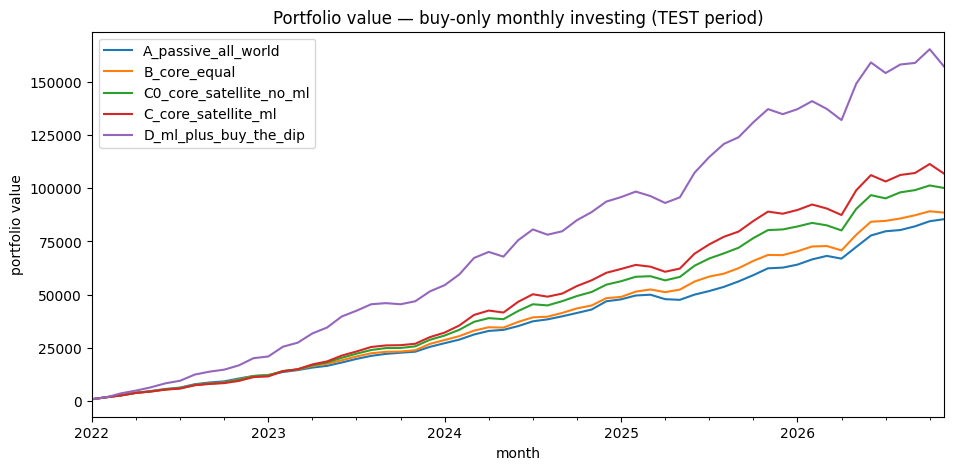

In [15]:
ax = curves.plot(figsize=(11, 5), title="Portfolio value — buy-only monthly investing (TEST period)")
ax.set_xlabel("month"); ax.set_ylabel("portfolio value"); plt.show()

## Step 6 — This month's buy list

In [16]:
buy = latest_buy_list(monthly, cfg)
buy.round(4)

,weight,amount,Close,proba
buy list 2026-11,,,,
EXS1.DE,0.175,175.0,214.10,0.5570
SPY,0.175,175.0,752.10,0.5367
QQQ,0.175,175.0,681.09,0.5699
VWRL.AS,0.175,175.0,163.64,0.5533
AVGO,0.100,100.0,322.23,0.7088
GOOG,0.100,100.0,278.04,0.6719
META,0.100,100.0,606.73,0.6568


In [17]:
# Save small result files (copy the summary into the README "Results" table)
tuning.to_csv(f"{cfg.OUTPUT_DIR}/tuning.csv", index=False)
summary.to_csv(f"{cfg.OUTPUT_DIR}/strategy_summary.csv", index=False)
curves.to_csv(f"{cfg.OUTPUT_DIR}/value_curves.csv")
buy.to_csv(f"{cfg.OUTPUT_DIR}/latest_buy_list.csv")
try:
    print(summary.round(4).to_markdown(index=False))   # Markdown table, ready to paste into README
except ImportError:                                    # 'tabulate' not installed
    print(summary.round(4).to_string(index=False))

| strategy                |   months |   invested |   final_value |   profit_multiple |    IRR |   TWR_CAGR |   max_drawdown |
|:------------------------|---------:|-----------:|--------------:|------------------:|-------:|-----------:|---------------:|
| A_passive_all_world     |       59 |      59000 |       85465.7 |            1.4486 | 0.1556 |     0.1044 |        -0.1051 |
| B_core_equal            |       59 |      59000 |       88504.6 |            1.5001 | 0.1706 |     0.1113 |        -0.1867 |
| C0_core_satellite_no_ml |       59 |      59000 |      100046   |            1.6957 | 0.2235 |     0.1616 |        -0.2007 |
| C_core_satellite_ml     |       59 |      59000 |      106689   |            1.8083 | 0.2515 |     0.1818 |        -0.2345 |
| D_ml_plus_buy_the_dip   |       59 |      80000 |      156815   |            1.9602 | 0.2629 |     0.1816 |        -0.2327 |
